# 02 · O que o DTW realmente compara: esqueleto, mãos e trajetórias

**Objetivo.** Abrir a “caixa-preta” do reconhecedor antes de medir seu desempenho.
O DTW não compara vídeos: compara dois vetores por frame, construídos a partir de
55 articulações canônicas. Este notebook mostra o que esses vetores preservam e o
que descartam.

**Perguntas orientadoras.**

1. Como é o esqueleto canônico de uma sequência `SIM` em treino, validação e teste?
2. A geometria da mão, depois da normalização pela palma, é estável entre
   informantes?
3. As trajetórias dos punhos se parecem entre informantes?
4. Qual é a escala da palma, a amplitude do punho e a energia de movimento em
   cada grupo?
5. Essas diferenças ajudam a explicar o colapso do teste?

**Definições usadas pelo runtime** (reproduzidas em `peter_eda.dtw`):

- **Forma da mão (168 dimensões):** para cada mão, 21 pontos × `(x, y, z, 1)`,
  relativos ao punho e divididos pela distância punho → quinta articulação do
  dedo médio (escala da palma). Pontos invisíveis viram quatro zeros; escala
  menor que 0,015 zera a mão inteira.
- **Trajetória (8 dimensões):** punho relativo ao ponto médio dos ombros,
  dividido pela largura dos ombros; `(x, y, z, 1)` por mão. Se qualquer frame
  não tiver os dois ombros, a trajetória da sequência inteira é descartada.
- **Reamostragem:** sequências com mais de 16 frames são reduzidas a 16 por
  índices igualmente espaçados (arredondamento do JavaScript).

In [1]:
import sys
from pathlib import Path

CWD = Path.cwd().resolve()
EDA_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (EDA_ROOT / "src" / "peter_eda").exists():
    raise RuntimeError(
        "Execute o notebook a partir de eda/ ou eda/notebooks/."
    )
sys.path.insert(0, str(EDA_ROOT / "src"))

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from peter_eda import config, dtw, loaders, manifest, metrics, quality, visualization

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
config.ensure_output_dirs()

dataset = loaders.load_dataset()


def show_paths(paths):
    # Show a mapping of name -> saved file, with the image inline.
    display(pd.Series(paths, name="figura").to_frame())
    for path in paths.values():
        display(Image(filename=str(path)))


print("EDA:", config.EDA_ROOT)
print("Projeto Peter:", config.PROJECT_ROOT)
print("Saídas:", config.OUTPUTS_DIR)

EDA: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda
Projeto Peter: C:\Users\henri\AppData\Local\Temp\opencode\peter_work
Saídas: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs


## 1. Três sequências `SIM`, uma por split

Para comparar sem selecionar “a melhor amostra”, usamos a primeira sequência
`SIM` de cada split: um template do informante 1, uma amostra de validação do
informante 4 e uma de teste do informante 5.

In [2]:
sim_train = next(s for s in dataset.templates if s.informant_id == "1")
sim_validation = next(
    s for s in dataset.evaluation if s.split == "validation" and s.class_name == "SIM"
)
sim_test = next(
    s for s in dataset.evaluation if s.split == "test" and s.class_name == "SIM"
)

selection = pd.DataFrame(
    [
        {
            "papel": role,
            "sample_id": sample.sample_id,
            "informante": sample.informant_id,
            "frames": sample.frame_count,
            "handCoverage": sample.hand_visibility,
            "shoulderCoverage": sample.pose_visibility,
        }
        for role, sample in (
            ("treino", sim_train),
            ("validação", sim_validation),
            ("teste", sim_test),
        )
    ]
)
display(selection)

,papel,sample_id,informante,frames,handCoverage,shoulderCoverage
0,treino,train-sim-train__SIM__INFORMANTE-1__IMG_0745,1,16,0.545500,1.0
1,validação,validation-sim-validation__SIM__INFORMANTE-4__IMG_0501,4,16,0.512821,1.0
2,teste,test-sim-test__SIM__INFORMANTE-5__IMG_1316,5,16,1.000000,1.0


## 2. Esqueleto canônico

A montagem mostra seis frames igualmente espaçados. O corpo usa 13 articulações;
as mãos são desenhadas separadamente (azul = esquerda, vinho = direita). Pontos
com visibilidade abaixo de 0,35 não são desenhados.

,figura
treino,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
validação,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
teste,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...


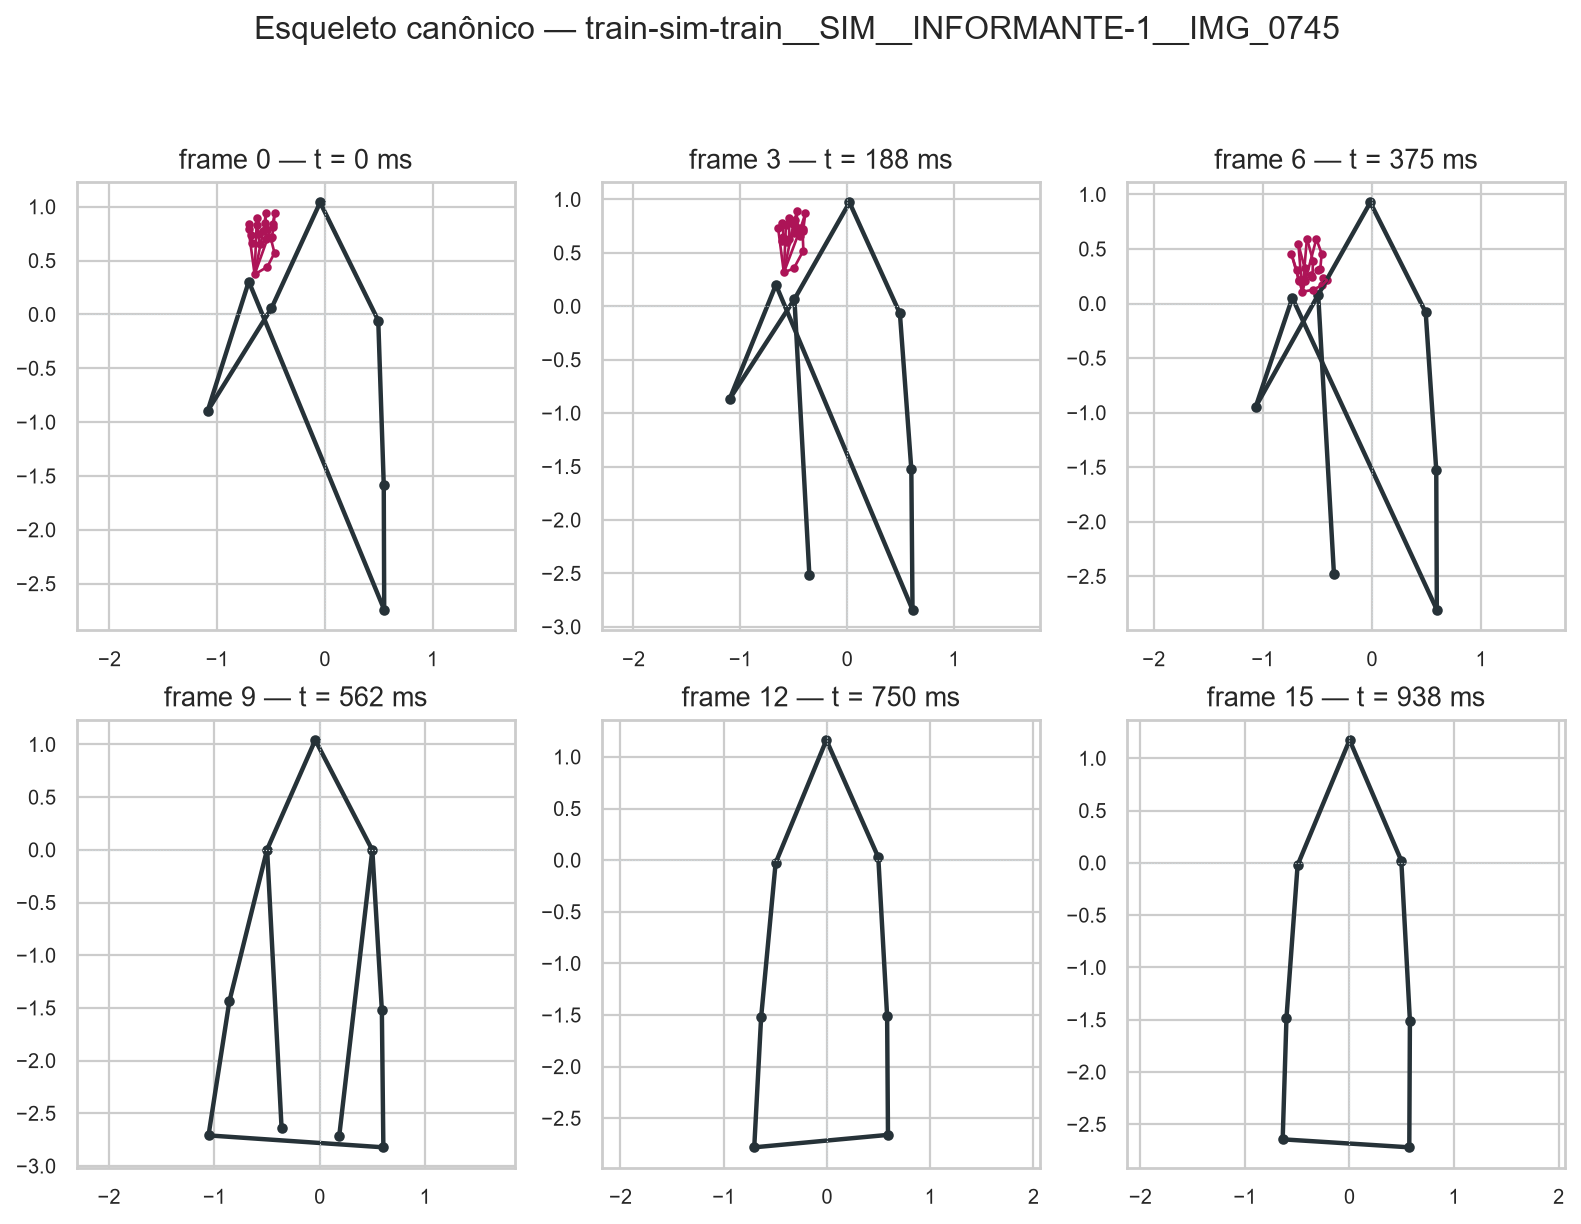

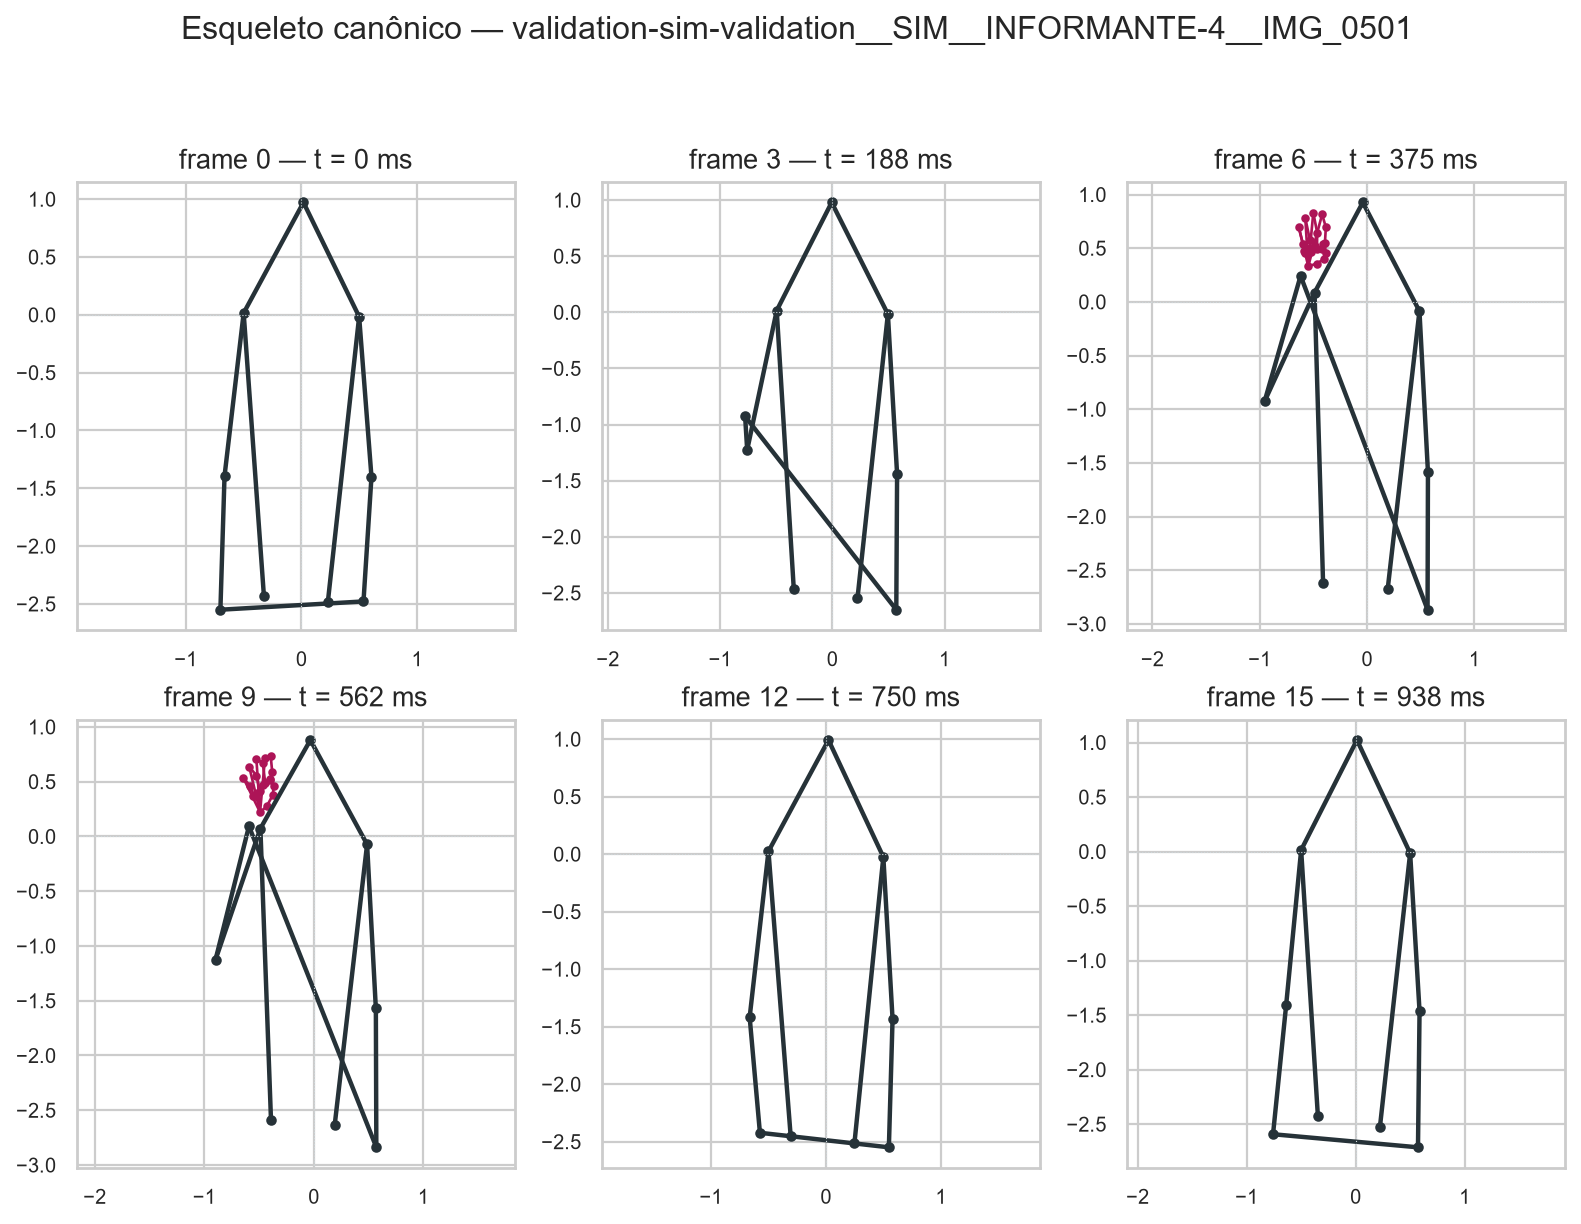

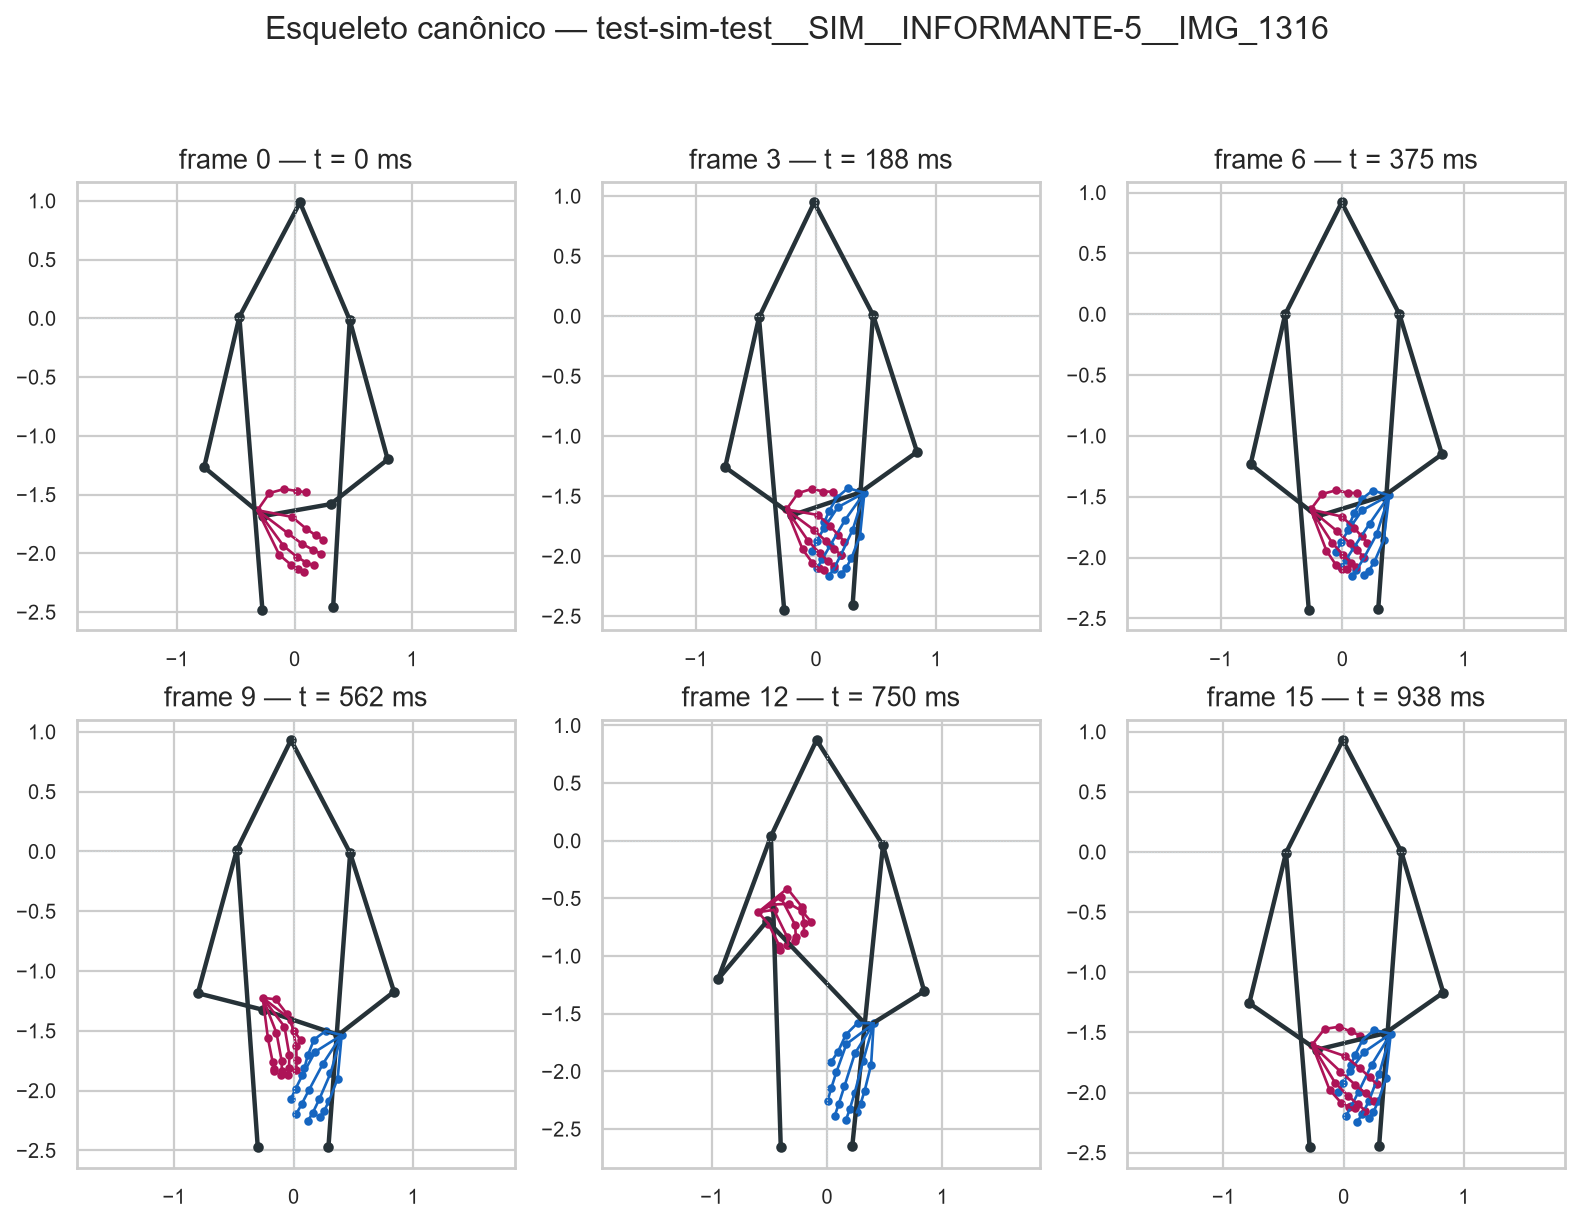

In [3]:
skeleton_paths = {
    "treino": visualization.plot_skeleton_montage(
        sim_train, filename="02_esqueleto_treino.png"
    ),
    "validação": visualization.plot_skeleton_montage(
        sim_validation, filename="02_esqueleto_validacao.png"
    ),
    "teste": visualization.plot_skeleton_montage(
        sim_test, filename="02_esqueleto_teste.png"
    ),
}
show_paths(skeleton_paths)

## 3. Geometria normalizada das mãos

A normalização pela palma remove tamanho absoluto da mão, mas **não** remove
diferenças de postura, orientação ou proporção entre dedos. É exatamente essa
geometria que entra nas 168 dimensões de forma.

,figura
treino,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
validação,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
teste,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...


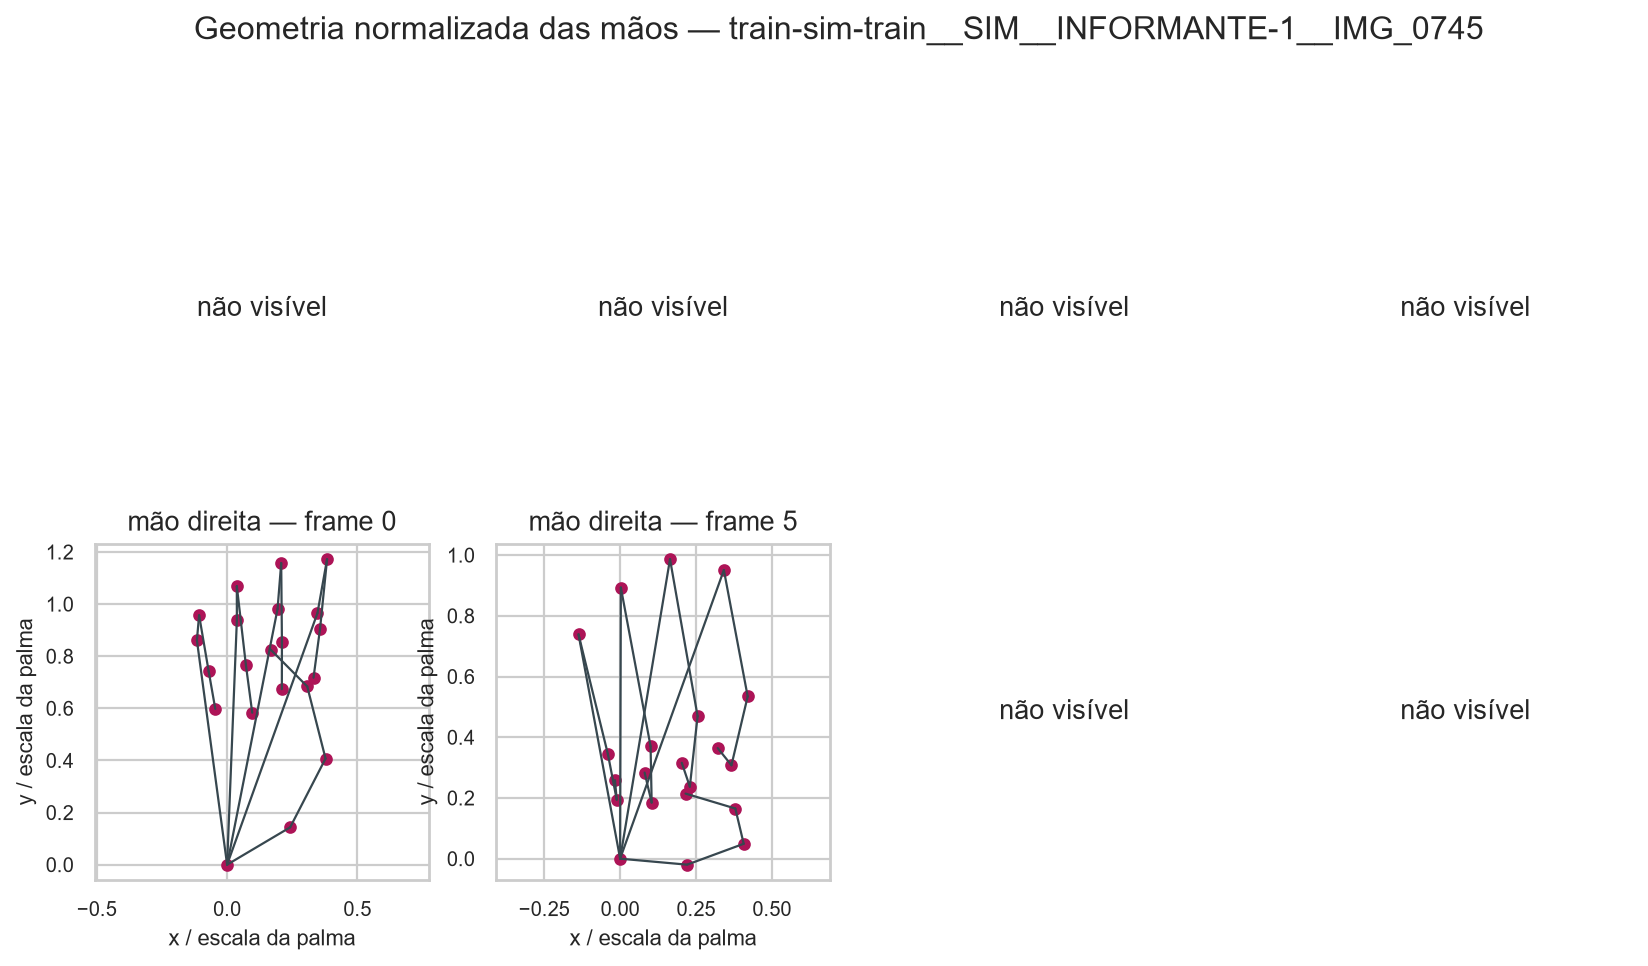

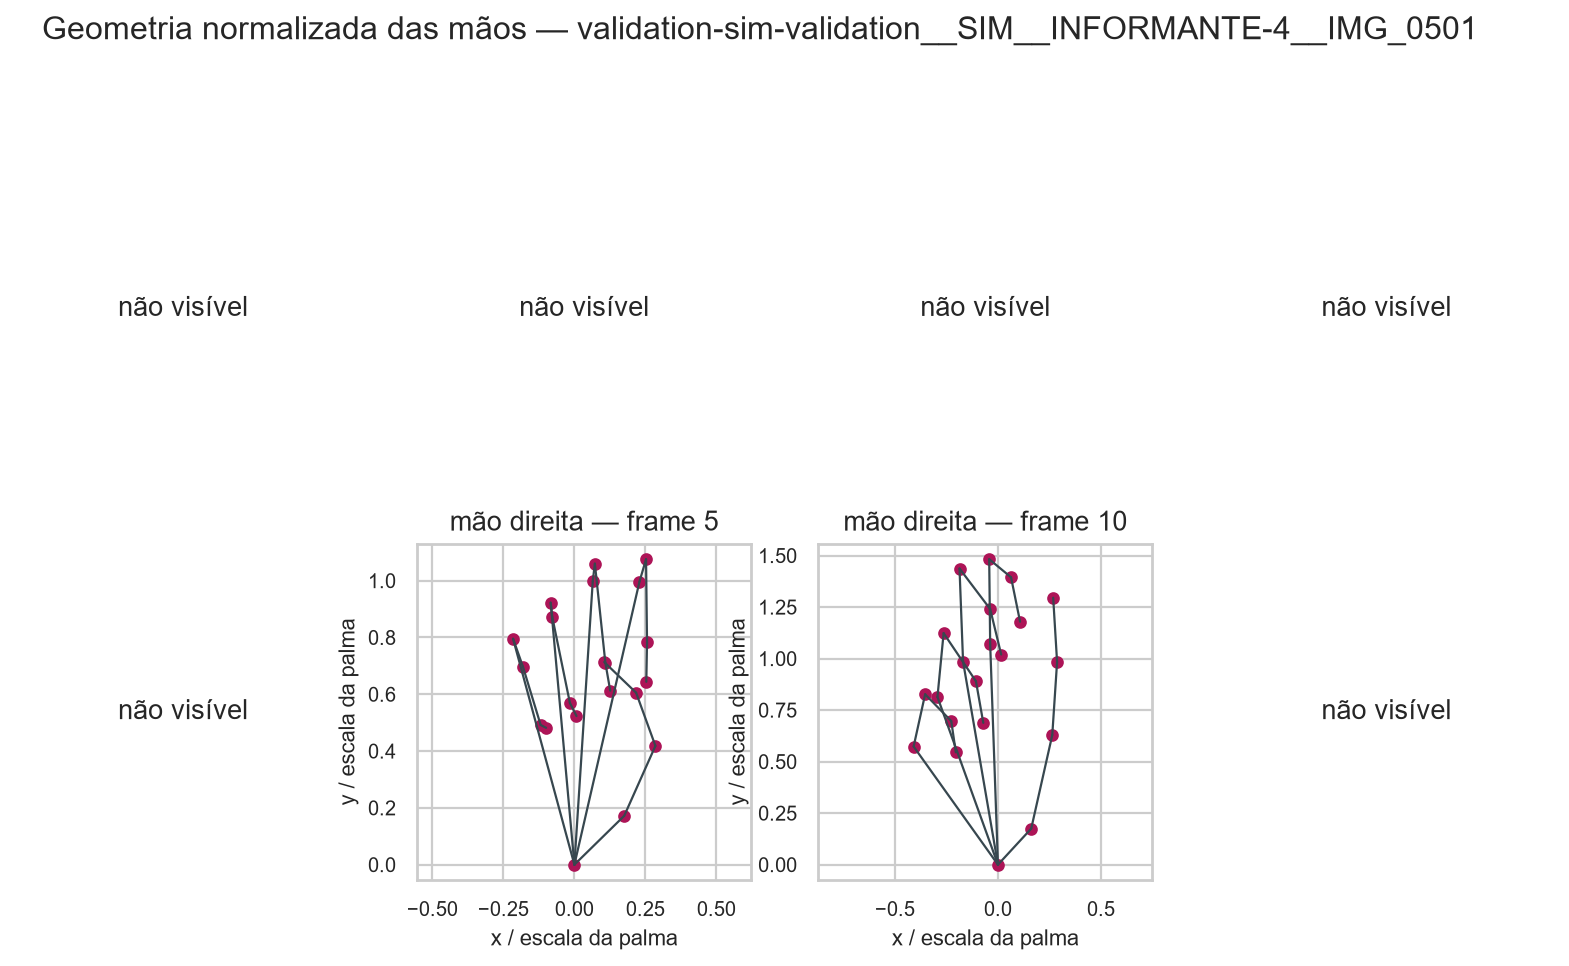

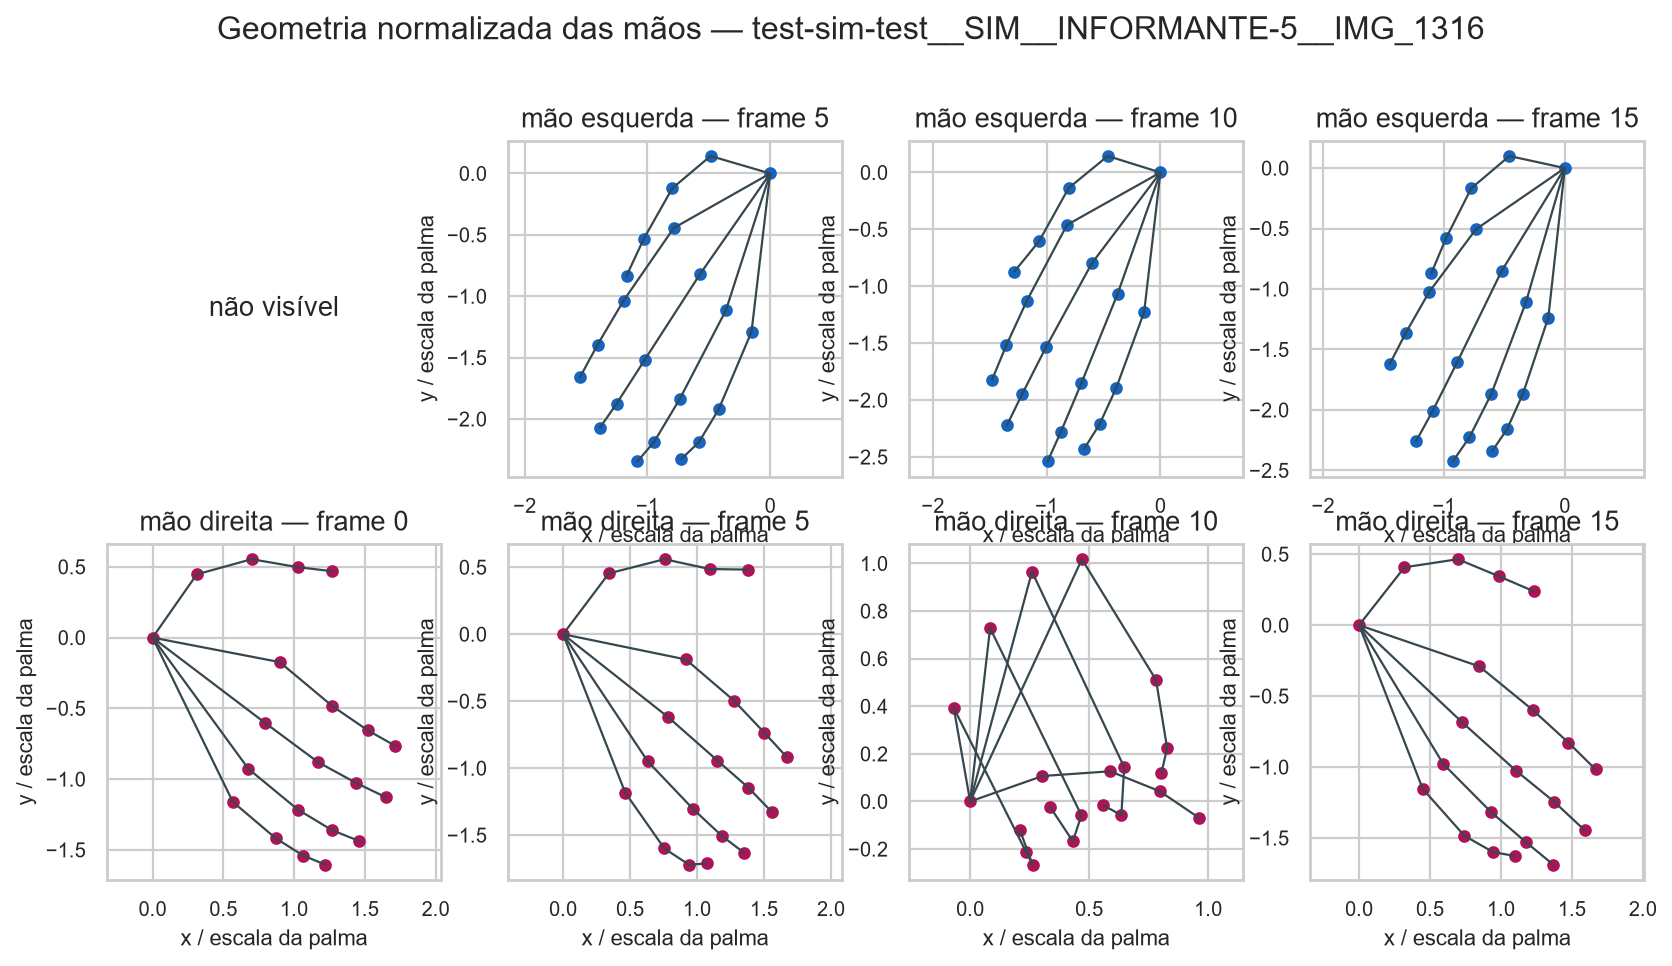

In [4]:
hand_paths = {
    "treino": visualization.plot_hand_shape_montage(
        sim_train, filename="02_forma_maos_treino.png"
    ),
    "validação": visualization.plot_hand_shape_montage(
        sim_validation, filename="02_forma_maos_validacao.png"
    ),
    "teste": visualization.plot_hand_shape_montage(
        sim_test, filename="02_forma_maos_teste.png"
    ),
}
show_paths(hand_paths)

## 4. Trajetórias dos punhos

Cada painel agrupa as sequências `SIM` de um informante. Linha contínua = punho
esquerdo; tracejada = punho direito; o marcador indica o primeiro frame. A
trajetória é o único componente que carrega informação temporal explícita de
posição do corpo.

por_informante    C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
comparada         C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02...
dtype: object

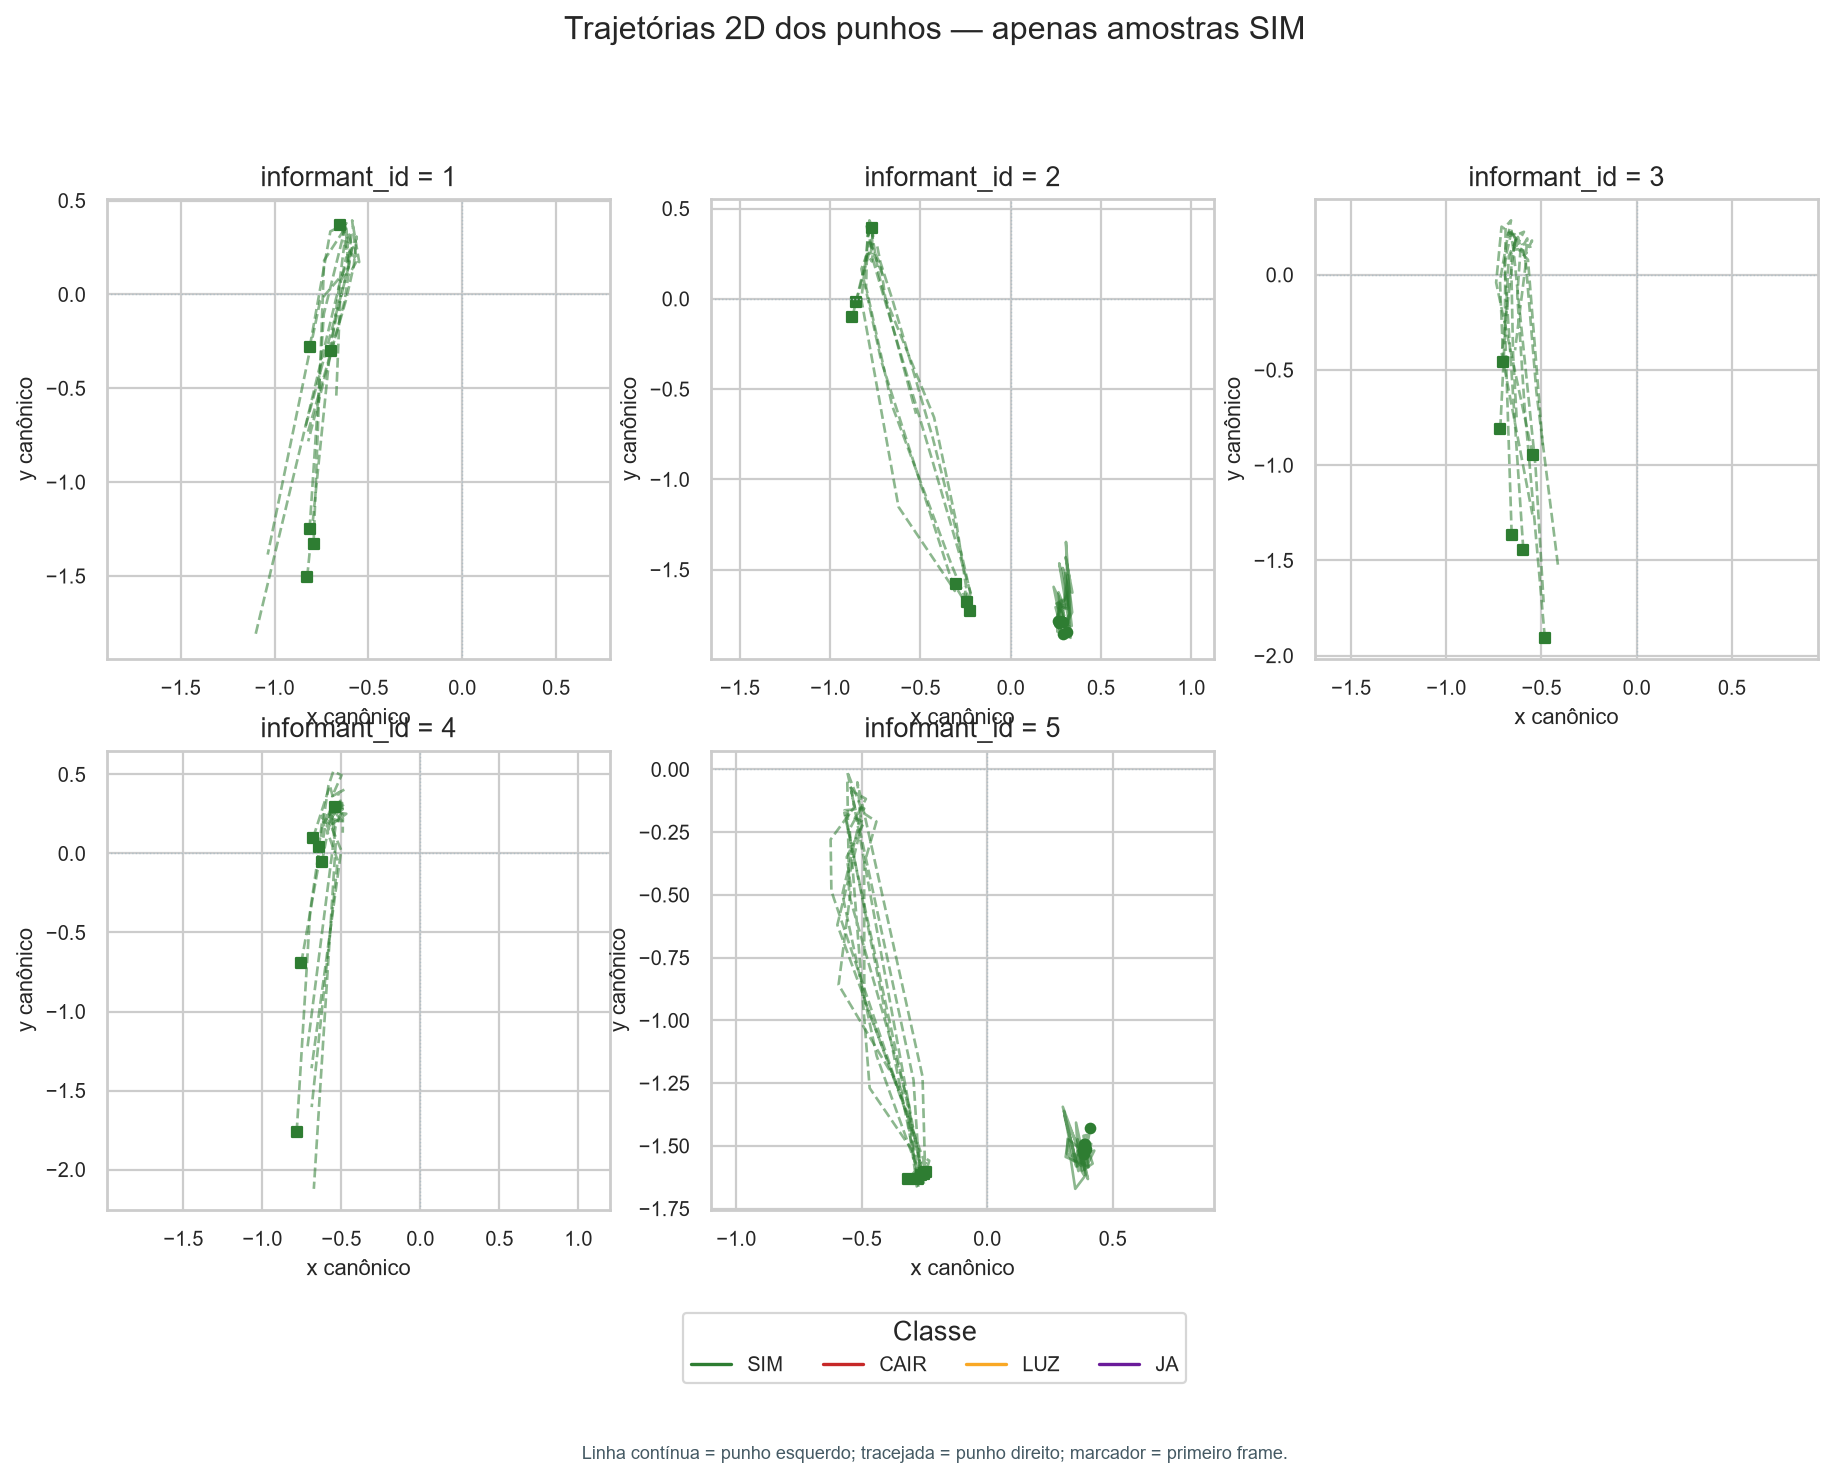

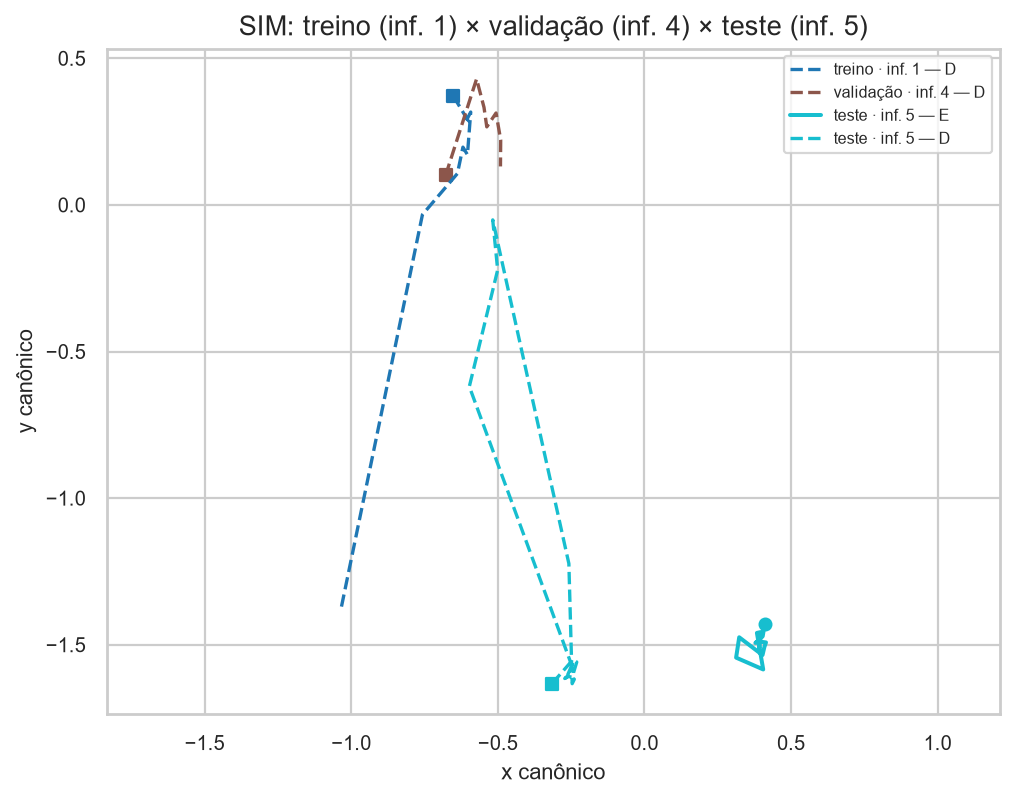

In [5]:
sim_samples = [s for s in dataset.active_samples if s.class_name == "SIM"]

trajectory_all = visualization.plot_wrist_trajectories(
    sim_samples,
    filename="02_trajetorias_por_informante.png",
    group_by="informant_id",
    title="Trajetórias 2D dos punhos — apenas amostras SIM",
)

trajectory_compare = visualization.plot_trajectory_comparison(
    [sim_train, sim_validation, sim_test],
    title="SIM: treino (inf. 1) × validação (inf. 4) × teste (inf. 5)",
    filename="02_trajetorias_comparadas.png",
    labels=["treino · inf. 1", "validação · inf. 4", "teste · inf. 5"],
)

display(pd.Series({"por_informante": trajectory_all, "comparada": trajectory_compare}))
for path in (trajectory_all, trajectory_compare):
    display(Image(filename=str(path)))

## 5. Animação de uma sequência de teste

O GIF permite verificar se a sequência é plausível e se a mão permanece visível
durante todo o movimento. Ele é salvo em `outputs/figures/02_animacao_teste.gif`.

GIF: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\02_animacao_teste.gif


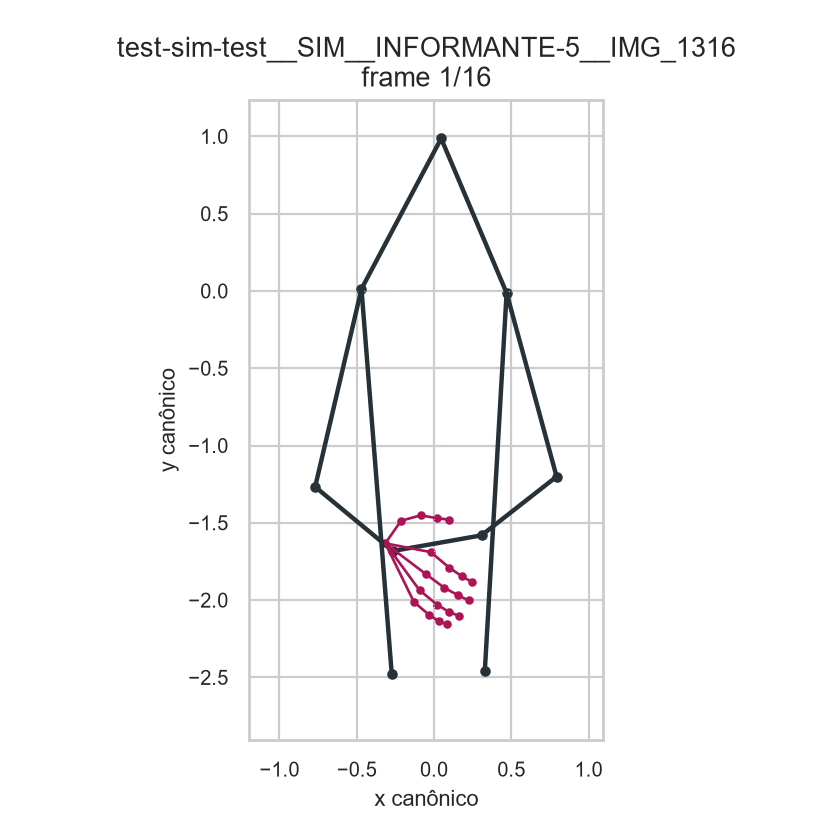

In [6]:
animation_path = visualization.animate_skeleton(
    sim_test, filename="02_animacao_teste.gif", fps=6
)
print("GIF:", animation_path)
display(Image(filename=str(animation_path)))

## 6. Medidas quantitativas do sinal

As três medidas abaixo resumem o que o DTW vê:

- **escala da palma**: média da distância punho → quinta articulação do dedo
  médio, nos frames em que ambos são visíveis;
- **amplitude do punho**: diagonal da caixa envolvente das posições 2D dos dois
  punhos ao longo da sequência;
- **energia de movimento**: média das distâncias por articulação entre frames
  consecutivos, incluindo punhos e ombros, como no runtime.

A tabela é gravada em `outputs/tables/signal_summary.csv`.

In [7]:
def palm_scale(frame):
    arrays = dtw.frame_to_arrays(frame)
    values = []
    for hand in ("left", "right"):
        wrist = arrays[hand][0]
        middle_mcp = arrays[hand][9]
        if wrist[3] >= config.MIN_VISIBILITY and middle_mcp[3] >= config.MIN_VISIBILITY:
            values.append(float(np.linalg.norm(wrist[:3] - middle_mcp[:3])))
    return float(np.mean(values)) if values else np.nan


def wrist_amplitude(sample):
    xs, ys = [], []
    for frame in sample.frames:
        arrays = dtw.frame_to_arrays(frame)
        for hand in ("left", "right"):
            wrist = arrays[hand][0]
            if wrist[3] >= config.MIN_VISIBILITY:
                xs.append(float(wrist[0]))
                ys.append(float(wrist[1]))
    if len(xs) < 2:
        return 0.0
    return float(np.hypot(np.ptp(xs), np.ptp(ys)))


signal_rows = []
for sample in dataset.active_samples:
    timestamps = [float(frame["timestamp"]) for frame in sample.frames]
    signal_rows.append(
        {
            "sample_id": sample.sample_id,
            "dataset_split": sample.split,
            "class_name": sample.class_name,
            "informant_id": sample.informant_id,
            "palm_scale_mean": float(np.nanmean([palm_scale(f) for f in sample.frames])),
            "wrist_amplitude": wrist_amplitude(sample),
            "motion_energy": dtw.motion_energy(sample.frames),
            "sequence_span_seconds": (timestamps[-1] - timestamps[0]) / 1000.0,
        }
    )

signal_summary = pd.DataFrame(signal_rows)
signal_path = config.output_path("table", "signal_summary.csv")
signal_summary.to_csv(signal_path, index=False, encoding="utf-8")

by_split = (
    signal_summary.groupby(["dataset_split", "class_name"])
    .agg(
        n=("sample_id", "count"),
        palm_scale_mean=("palm_scale_mean", "mean"),
        wrist_amplitude_mean=("wrist_amplitude", "mean"),
        motion_energy_mean=("motion_energy", "mean"),
        span_seconds=("sequence_span_seconds", "mean"),
    )
    .round(3)
    .reset_index()
)
display(by_split)

sim_by_informant = (
    signal_summary[signal_summary["class_name"] == "SIM"]
    .groupby(["dataset_split", "informant_id"])
    .agg(
        n=("sample_id", "count"),
        palm_scale_mean=("palm_scale_mean", "mean"),
        wrist_amplitude_mean=("wrist_amplitude", "mean"),
        motion_energy_mean=("motion_energy", "mean"),
    )
    .round(3)
    .reset_index()
)
display(sim_by_informant)
print("Tabela:", signal_path)

,dataset_split,class_name,n,palm_scale_mean,wrist_amplitude_mean,motion_energy_mean,span_seconds
0,test,CAIR,6,0.340,2.896,0.354,0.938
1,test,JA,6,0.291,1.661,0.182,0.938
2,test,LUZ,6,0.276,3.082,0.255,0.938
3,test,SIM,6,0.317,1.851,0.185,0.938
4,train,SIM,18,0.389,1.972,0.440,0.938
5,validation,CAIR,6,0.434,1.912,0.905,0.938
6,validation,JA,6,0.350,1.027,0.687,0.938
7,validation,LUZ,6,0.349,3.034,0.665,0.938
8,validation,SIM,6,0.464,1.482,0.430,0.938


,dataset_split,informant_id,n,palm_scale_mean,wrist_amplitude_mean,motion_energy_mean
0,test,5,6,0.317,1.851,0.185
1,train,1,6,0.424,1.743,0.576
2,train,2,6,0.325,2.490,0.264
3,train,3,6,0.419,1.683,0.480
4,validation,4,6,0.464,1.482,0.430


Tabela: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\tables\signal_summary.csv


**Leitura dos números.** A escala média da palma nos `SIM` é ~0,42 (inf. 1),
~0,33 (inf. 2), ~0,42 (inf. 3), ~0,46 (validação, inf. 4) e ~0,32 (teste,
inf. 5). O teste é, portanto, o grupo com mão **menor** em relação ao próprio
punho, e é justamente o grupo cujos melhores templates vêm do informante 2
(escala ~0,33).

A energia de movimento dos `SIM` cai de ~0,43 na validação para ~0,19 no teste,
enquanto a amplitude do punho é semelhante (~1,5 vs ~1,9). Ou seja, o teste não é
um movimento “parado”: é um movimento com deslocamento comparável, mas com menos
variação frame a frame. A trajetória continua informativa; a forma da mão é que
muda de escala e de postura.

## 7. Conclusões do notebook

1. O DTW compara **forma normalizada da mão** (168 dimensões) e **trajetória
   normalizada dos punhos** (8 dimensões). Não há informação de velocidade,
   orientação global ou texto.
2. As três sequências `SIM` são visualmente plausíveis; a de teste não está
   corrompida nem sem mãos.
3. A escala da palma e a energia de movimento do informante 5 diferem das do
   treino e da validação. A semelhança de escala com o informante 2 explica por
   que seus templates vencem no teste, mas não garante boa pontuação absoluta.
4. A análise visual é sugestiva, não conclusiva. O notebook 04 mede diretamente
   a separação de scores e a distância entre informantes.

## 8. Limitações deste notebook

- Mostramos uma sequência por split; as conclusões numéricas usam todas as 66
  amostras, mas as imagens são ilustrativas.
- A escala da palma é sensível à qualidade dos landmarks da mão; com
  `handCoverage` alto no teste, esse ruído deve ser pequeno, mas não é medido.
- O GIF e as montagens usam coordenadas canônicas já normalizadas; não é
  possível reconstruir a pose 3D original nem avaliar erro de extração.
- A rotação global da mão não é visualizada em 3D; a projeção 2D pode esconder
  diferenças de orientação que afetam o DTW.